In [1]:
#Import Packages
import numpy as np
import pandas as pd
import datetime
import random
import time
import string
from matplotlib import pyplot as plt
from iteration_utilities import unique_everseen
from iteration_utilities import duplicates
%matplotlib inline
VERBOSE = False
SEED = 213
random.seed(SEED)

In [2]:
#Base Code from book
def quick_sort(array):
  if len(array) < 2:
    # base case, arrays with 0 or 1 element are already "sorted"
    return array
  else:
    # recursive case
    pivot = array[0]
    # sub-array of all the elements less than the pivot
    less = [i for i in array[1:] if i <= pivot]
    # sub-array of all the elements greater than the pivot
    greater = [i for i in array[1:] if i > pivot]
    return quick_sort(less) + [pivot] + quick_sort(greater)

In [3]:
#Bubble Sort
def bubble_sort(xlist):
    n = len(xlist)
    
    #Traverse array
    for i in range(n):
        # Last i elements are already in place
        for j in range(0, n-i-1):
            #Traverse array from 0 to n-i-1
            #Swap if element found is greater than next element
            if xlist[j] > xlist[j+1]:
                xlist[j], xlist[j+1] = xlist[j+1], xlist[j]
    return xlist

In [4]:
#Insertion Sort
def insertion_sort(xlist):
    # Traverse list
    for i in range(1, len(xlist)):
        key = xlist[i]
        # Move elements of array[0..i-1] that are greater than key,
        # one position ahead of their current place
        j = i-1
        while j >= 0 and key < xlist[j]:
            xlist[j+1] = xlist[j]
            j-=1
        xlist[j+1] = key
    return xlist

### 1) Set up five lists of randomly generated strings of characters (i.e. a-z or A-Z e.g. abcdefkjklkjlkjlkjkljlkjlkjlkjkljasdfgtredghjkiuyt). Each string should be 50 characters long. The first list should have 200 strings (each string should be 50 characters long), second should have 400 strings (again each string is 50 characters), third 600 (same length strings i.e. 50 characters), fourth 800 (string length continues to be 50 characters), and last/fifth 1000 strings (yes 50 characters in each string). 

In [5]:
#Function to generate string of characters
def generate (length):
    x_list = []
    for j in range(length):       
        x = ''
        
        for i in range(50):
            randomLetter = random.choice(string.ascii_letters)
            x = randomLetter + x
            string_lower = x.lower()
            
        x_list.append(string_lower)
        
    return x_list  

In [6]:
#Five randomly generated strings of characters
string_200 = generate(200)
string_400 = generate(400)
string_600 = generate(600)
string_800 = generate(800)
string_1000 = generate(1000)

### 2) You may use the code we used in previous homework assignments.  Make sure the list is unsorted and does not contain any duplicates.

In [7]:
string_200

['ygobyxqwhvjcknrurugwsyllrkzmytddjvmnhbwktgiambsoaj',
 'vforeconuhobfwwtzpbitalngoqamznhtlznhjenrqovrjtygq',
 'trxuawhkzwpoqkhaucujesbpvdcropzxguceikvhalsbsiasrp',
 'xelycyypkoldihpylfqnjlungzhauvfqthrntvdjtkqhvxskxy',
 'xfslhnoskwtcyzolbmeduwvufqaihpokxjosxougfuzisnonph',
 'qlzdultslliotumlocbslxamvfecybbpwaaqrsrtjdbhvokfoo',
 'rjcjgxlqwtehkdavpfligwdrucyvqndshhamclciaaqwkqsmks',
 'pnjkjwejrmglrsivlhgjuyphfgjyexjlhczmkodpfsqlrworpe',
 'mzzbtxdosqjgizixmnnfgylxxeqagxgdneccpbdkddtvpzjxnk',
 'yqeyptazkhanuqqqogijcuxqnjmkyfvgxhptiffqakoqnzrezg',
 'qdiprcynknjbooeveqcaqwmfmtczwsladmlugapekcgeawgucf',
 'wnjosuwmnygwiglsunsmfhbdebshjpfmentpjpdkuewhlchekp',
 'calfnjasjikxzcnvfxuxrtagkudatmxcegbhhruuaawrymjdis',
 'yymjbckfvufdqtonckmciiahvilnehghgsxesrzjkgejvgnzxr',
 'vfvbsqqscdnflgqsrjsozpfyfelvuqbiqixsfcihklojwezeiw',
 'vmpeaksujegocstwlzgcchtbptchkxstaonyouhjvaptfkrryp',
 'qeajtymqsybtwdeuuvnsacwvxsdbpbdlnoxhvcaoiuazlyypln',
 'gweriknqwifuiqvvtovnwyitchhfzudznunwxktsjqwtyylixl',
 'lxrrjabv

In [8]:
list(unique_everseen(duplicates(string_200)))

[]

### 3) Use the textbook implementation of quicksort to sort the data, being sure to capture the amount of time it takes for each list. 

In [9]:
# Time a sorting function on a copy of the data (bubble and insertion sort work in place,
# so every algorithm gets the same unsorted input). Best of five runs, in milliseconds.
def time_sort(sort_function, data, runs=5):
    best = float('inf')
    for r in range(runs):
        data_copy = list(data)
        start_time = time.perf_counter()
        sort_function(data_copy)
        end_time = time.perf_counter()
        best = min(best, (end_time - start_time) * 1000)
    return best

lists = [string_200, string_400, string_600, string_800, string_1000]

#Quick Sort Algorithm
quickSort = [time_sort(quick_sort, x) for x in lists]

In [10]:
#create dataframe for quicksort time
qs = {'Quick Sort' : quickSort}
quicksort_df = pd.DataFrame(data=qs)
quicksort_df

,Quick Sort
0,0.215061
1,0.440140
2,0.679994
3,0.944963
4,1.252569


### 4) Now use at least two other sorting algorithms on the same data set (e.g. merge sort, bubble sort, insertion sort, etc).  Make sure that you code the sorting algorithm and you do not use a builtin function. By this I mean you may not use np.sort() or sorted(), etc.  You must code the algorithm in order to compare the complexity of each.  Here is a good resource https://www.geeksforgeeks.org/sorting-algorithms/ (Links to an external site.)).  Capture the computation time for each list using each sorting algorithm that you have used.  

In [11]:
#Bubble Sort
bubbleSort = [time_sort(bubble_sort, x) for x in lists]

In [12]:
#Insertion Sort
insertionSort = [time_sort(insertion_sort, x) for x in lists]

### 5) Create a table containing each algorithm and the timings for each list.  Provide a graph showing how each algorithm scales with size of list (also compare the algorithms themselves).  Discuss your findings with explanations for what you observe. 

In [13]:
sort_times = {'List Length': [200, 400, 600, 800, 1000],
    'Quick Sort' : quickSort,
           'Bubble Sort' : bubbleSort,
           #'merge sort': mergesort_times,
           'Insertion Sort' : insertionSort}
sort_times = pd.DataFrame(data=sort_times)
# all times in milliseconds
sort_times


,List Length,Quick Sort,Bubble Sort,Insertion Sort
0,200,0.215061,1.203175,0.445513
1,400,0.440140,4.969046,1.880302
2,600,0.679994,11.166460,4.495073
3,800,0.944963,21.266117,7.983994
4,1000,1.252569,31.995680,13.411592


Text(0.5, 1.0, 'Sort Time for Different Sorting Algorithms')

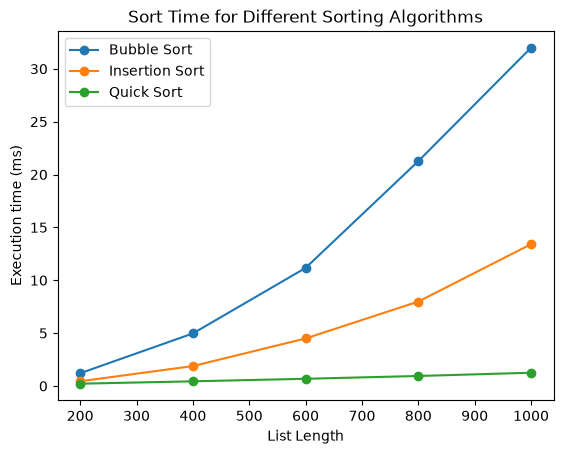

In [14]:
#graph results
plt.plot(sort_times['List Length'], sort_times['Bubble Sort'], marker='o')
plt.plot(sort_times['List Length'], sort_times['Insertion Sort'], marker='o')
plt.plot(sort_times['List Length'], sort_times['Quick Sort'], marker='o')
plt.legend(('Bubble Sort', 'Insertion Sort', 'Quick Sort'))
plt.ylabel('Execution time (ms)')
plt.xlabel('List Length')
plt.title('Sort Time for Different Sorting Algorithms')

# EXECUTIVE SUMMARY

### Introduction

This report analyzed the speed of the quick sort algorithm by comparing it to the speed of the bubble sort algorithm, and by comparing it to the speed of the insertion sort algorithm. A of set of five random lists were generated composed of the following lengths: n = 200, 400, 600, 800, 1000. The algorithms sorted the values in the lists from smallest to largest to measure sort times for how efficiently they performed, but how capable they are for handling scalability. 

### Quick Sort 

The quick sort algorithm uses a divide-and-conquer strategy to break down a list or an array into its base case. It uses an element in either object to pivot to determine the values less than and more than the pivot value. As it runs, the alrogithm partitions the object into sub-objects.  

### Industry Application

The quicksort algorithm is practical and efficient because of how it is able to help an organization scales its operations. Not only do popular search enginges like Google, Bing, DuckDuckGo, etc. use quicksort to help retrieve data, but companies like Apple, Meta, Amazon, etc. use quicksort to manage their value. The common factor is that regardless if the organization produces, holds, or analyzes large datasets, the quicksort algorithm is frequently used in daily applications to ensure the system remains within optimal parameters for stakeholders.  

### Methodology

Five random lists were generated using the generate function. The list values were: n = 200, 400, 600, 800, and 1000. For each list length, the execution time of the quicksort algorithm was appended to a list created to store the values for execution time. Every algorithm sorted its own copy of the same unsorted list, and the best of five runs was recorded in milliseconds. The bubble sort algorithm and the insertion sort algorithm were used only for their comparative values and will not be discussed in further detail. 

### Analysis & Results

The results displayed on table 1 show that the quick sort algorithm is the fastest of the three at every list length. For a list of n = 200, the quick sort execution time is 0.215 milliseconds, the bubble sort execution time is 1.203 milliseconds, and the insertion sort execution time is 0.446 milliseconds. Doubling the list length to n = 400, the quick sort takes 0.440 milliseconds, bubble sort 4.969 milliseconds and insertion sort 1.880 milliseconds. Doubling the list roughly doubles the quick sort time but roughly quadruples the bubble sort and insertion sort times. At n = 1000 the quick sort takes 1.253 milliseconds, compared with 31.996 milliseconds for bubble sort and 13.412 milliseconds for insertion sort. Going from 200 to 1000 strings (5 times longer) multiplied the quick sort time by about 6, in line with O(n log n), and the bubble and insertion sort times by about 27 and 30, in line with O(n^2).

### Discussion of Big O Notation

Big O notation for the quicksort algorithm is O(n log n) on average and O(n^2) in the worst case. When the pivot splits the list roughly in half, the call stack is O(log n) levels deep and each level does O(n) work, which gives O(n log n). When every split is lopsided, as with an already sorted list and the first element as the pivot, the call stack is O(n) levels deep and the run time is O(n^2). Bubble sort and insertion sort are O(n^2) on random data; insertion sort drops to O(n) on a list that is already sorted.

### Conclusion

The execution speed of the quicksort algorithm read in Big O notation is given as O(n log n) or O(n^2). This is important given that data storage and resources necessitate a dynamic strategy to remain optimal in performance and management. With quicksort being used daily in numerous platforms and applications, it is a practical implementation for data systems.   